In [1]:
import pandas as pd
import numpy as np

# Загружаем официальные train/test выборки
train = pd.read_csv("../data/raw/UNSW_NB15_training-set.csv")
test  = pd.read_csv("../data/raw/UNSW_NB15_testing-set.csv")

print("Train:", train.shape)
print("Test: ", test.shape)

Train: (175341, 45)
Test:  (82332, 45)


In [2]:
train.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [3]:
train.info()
print("\nПропуски (топ-10 столбцов):")
print(train.isna().sum().sort_values(ascending=False).head(10))

<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  str    
 3   service            175341 non-null  str    
 4   state              175341 non-null  str    
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  int64  
 16  sinpkt       

In [4]:
print("Полных дубликатов:", train.duplicated().sum())

print("\nРаспределение label (0 = Normal, 1 = Attack):")
print(train["label"].value_counts())
print(train["label"].value_counts(normalize=True).round(4))

print("\nКатегории атак:")
print(train["attack_cat"].value_counts())

Полных дубликатов: 0

Распределение label (0 = Normal, 1 = Attack):
label
1    119341
0     56000
Name: count, dtype: int64
label
1    0.6806
0    0.3194
Name: proportion, dtype: float64

Категории атак:
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


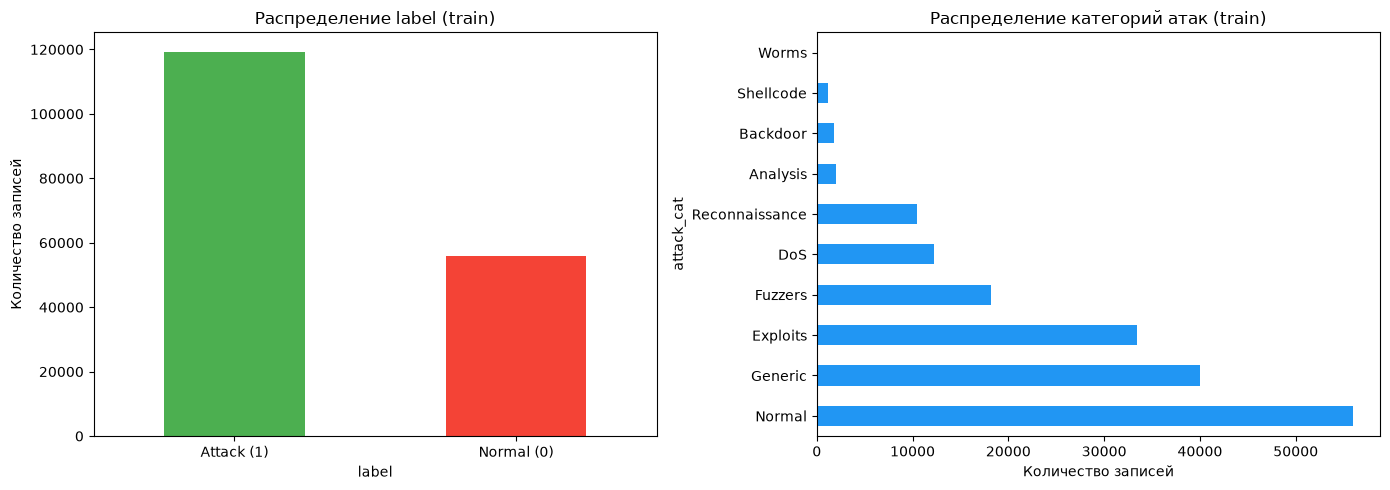

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: Normal vs Attack
train["label"].value_counts().plot(
    kind="bar", ax=axes[0], color=["#4CAF50", "#F44336"]
)
axes[0].set_title("Распределение label (train)")
axes[0].set_xticklabels(["Attack (1)", "Normal (0)"], rotation=0)
axes[0].set_ylabel("Количество записей")

# График 2: категории атак
train["attack_cat"].value_counts().plot(
    kind="barh", ax=axes[1], color="#2196F3"
)
axes[1].set_title("Распределение категорий атак (train)")
axes[1].set_xlabel("Количество записей")

plt.tight_layout()
plt.savefig("../reports/01_class_distribution.png", dpi=150)
plt.show()

In [6]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
id,175341.0,8.767100e+04,5.061673e+04,1.0,43836.000000,87671.000000,1.315060e+05,1.753410e+05
dur,175341.0,1.359389e+00,6.480249e+00,0.0,0.000008,0.001582,6.680690e-01,5.999999e+01
spkts,175341.0,2.029866e+01,1.368876e+02,1.0,2.000000,2.000000,1.200000e+01,9.616000e+03
dpkts,175341.0,1.896959e+01,1.102583e+02,0.0,0.000000,2.000000,1.000000e+01,1.097400e+04
sbytes,175341.0,8.844844e+03,1.747656e+05,28.0,114.000000,430.000000,1.418000e+03,1.296523e+07
dbytes,175341.0,1.492892e+04,1.436542e+05,0.0,0.000000,164.000000,1.102000e+03,1.465555e+07
rate,175341.0,9.540619e+04,1.654010e+05,0.0,32.786140,3225.806520,1.250000e+05,1.000000e+06
sttl,175341.0,1.795470e+02,1.029400e+02,0.0,62.000000,254.000000,2.540000e+02,2.550000e+02
dttl,175341.0,7.960957e+01,1.105069e+02,0.0,0.000000,29.000000,2.520000e+02,2.540000e+02
sload,175341.0,7.345403e+07,1.883574e+08,0.0,13053.338870,879674.750000,8.888889e+07,5.988000e+09


In [7]:
cat_cols = train.select_dtypes(include="object").columns.tolist()
print("Категориальные столбцы:", cat_cols)

for col in cat_cols:
    print(f"\n{col}: уникальных = {train[col].nunique()}")
    print(train[col].value_counts().head(8))

Категориальные столбцы: ['proto', 'service', 'state', 'attack_cat']

proto: уникальных = 133
proto
tcp     79946
udp     63283
unas    12084
arp      2859
ospf     2595
sctp     1150
any       300
gre       225
Name: count, dtype: int64

service: уникальных = 13
service
-           94168
dns         47294
http        18724
smtp         5058
ftp-data     3995
ftp          3428
ssh          1302
pop3         1105
Name: count, dtype: int64

state: уникальных = 9
state
INT    82275
FIN    77825
CON    13152
REQ     1991
RST       83
ECO       12
PAR        1
URN        1
Name: count, dtype: int64

attack_cat: уникальных = 10
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Name: count, dtype: int64


C:\Users\User\AppData\Local\Temp\ipykernel_5064\1546841413.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = train.select_dtypes(include="object").columns.tolist()


In [8]:
num_cols = train.select_dtypes(include=[np.number]).columns.drop(["id", "label"])

corr_with_label = train[num_cols].corrwith(train["label"]).sort_values()

print("Топ-8 признаков, НАИБОЛЕЕ связанных с атакой:")
print(corr_with_label.tail(8))
print("\nТоп-8, связанных с нормальным трафиком (отриц. корреляция):")
print(corr_with_label.head(8))

Топ-8 признаков, НАИБОЛЕЕ связанных с атакой:
ct_dst_ltm          0.229887
ct_src_ltm          0.238225
ct_dst_src_ltm      0.303855
ct_src_dport_ltm    0.305579
rate                0.337979
ct_dst_sport_ltm    0.357213
ct_state_ttl        0.577704
sttl                0.692741
dtype: float64

Топ-8, связанных с нормальным трафиком (отриц. корреляция):
dload             -0.393739
dmean             -0.341806
swin              -0.333633
dwin              -0.319626
stcpb             -0.255006
dtcpb             -0.250340
is_sm_ips_ports   -0.184679
sinpkt            -0.176110
dtype: float64


In [9]:
print("Всего пропусков в train:", train.isna().sum().sum())
print("Всего пропусков в test: ", test.isna().sum().sum())

Всего пропусков в train: 0
Всего пропусков в test:  0
